In [21]:
import os
import glob
import zipfile
import warnings
import numpy as np
import pandas as pd
from scipy.linalg import svd, eigh
from scipy.spatial.distance import pdist, squareform
from scipy.stats import mannwhitneyu, levene
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 140
plt.rcParams["savefig.bbox"] = "tight"

def participation_ratio(vec):
    """Нормализованный коэффициент участия PR в [1/N, 1]."""
    v = np.asarray(vec, dtype=float)
    p = (v ** 2) / np.sum(v ** 2)
    return float(1.0 / (len(v) * np.sum(p ** 2)))

def run_first_echelon_bypass(X_raw, labels):
    """Первый эшелон (Bypass): Z-score стандартизация + SVD."""
    X_z = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)
    U, S, Vt = svd(X_z, full_matrices=False)
    energy = (S ** 2) / np.sum(S ** 2)
    weights_v1 = Vt[0, :] ** 2
    order = np.argsort(weights_v1)[::-1]
    top_idx = int(order.item(0))
    return {
        "U": U, "S": S, "Vt": Vt,
        "energy_1": float(energy.item(0)),
        "pr_u1": participation_ratio(U[:, 0]),
        "pr_v1": participation_ratio(Vt[0, :]),
        "weights_v1": weights_v1,
        "order": order,
        "top_label": labels[top_idx],
        "top_share": float(weights_v1[top_idx])
    }

def bootstrap_pr(X_raw, n_iter=300, frac=0.8, seed=42):
    """Бутстрэп-проверка устойчивости PR(u1) и PR(v1) (субсэмплирование без возвращения)."""
    rng = np.random.default_rng(seed)
    n_samples = len(X_raw)
    sub_size = int(frac * n_samples)
    pr_u, pr_v = [], []
    for _ in range(n_iter):
        idx = np.sort(rng.choice(n_samples, size=sub_size, replace=False))
        X_sub = X_raw[idx]
        X_z = (X_sub - X_sub.mean(axis=0)) / X_sub.std(axis=0)
        U_b, _, Vt_b = svd(X_z, full_matrices=False)
        pr_u.append(participation_ratio(U_b[:, 0]))
        pr_v.append(participation_ratio(Vt_b[0, :]))
    return {
        "u1_ci": (float(np.percentile(pr_u, 2.5)), float(np.percentile(pr_u, 97.5))),
        "v1_ci": (float(np.percentile(pr_v, 2.5)), float(np.percentile(pr_v, 97.5)))
    }

def build_lsym_and_fiedler(X_mat, k_nn=6):
    """Второй эшелон: построение k-NN графа сходства и L_sym."""
    dist = squareform(pdist(X_mat, metric="euclidean"))
    sigma = float(np.median(dist[dist > 0]))
    W = np.exp(- (dist ** 2) / (2.0 * sigma ** 2))
    np.fill_diagonal(W, 0.0)
    n_nodes = len(W)
    k_eff = min(k_nn, n_nodes - 2)
    for i in range(n_nodes):
        W[i, np.argsort(W[i])[::-1][k_eff:]] = 0.0
    W = 0.5 * (W + W.T)
    deg = np.sum(W, axis=1)
    d_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(deg, 1e-12)))
    L_sym = np.eye(n_nodes) - d_inv_sqrt @ W @ d_inv_sqrt
    evals, evecs = eigh(L_sym)
    gap = float(evals.item(1) - evals.item(0))
    return W, evals, evecs, gap

def leave_one_out_scan(X_diff_z, years_diff, labels, scan_range, test_type="mean", k_nn=6):
    """Слепой поиск точки перелома + тест устойчивости Leave-One-Out по столбцам."""
    _, _, evecs_base, _ = build_lsym_and_fiedler(X_diff_z, k_nn=k_nn)
    u2_base = evecs_base[:, 1]

    p_scan = []
    for y in scan_range:
        idx = int(np.searchsorted(years_diff, y))
        if test_type == "mean":
            _, p = mannwhitneyu(u2_base[:idx], u2_base[idx:])
        else:
            _, p = levene(u2_base[:idx], u2_base[idx:], center="median")
        p_scan.append(float(p))

    best_yr = int(scan_range[int(np.argmin(p_scan))])
    min_p = float(np.min(p_scan))
    idx_best = int(np.searchsorted(years_diff, best_yr))

    loo_results = {}
    for j, name in enumerate(labels):
        keep = [i for i in range(len(labels)) if i != j]
        _, _, evecs_sub, _ = build_lsym_and_fiedler(X_diff_z[:, keep], k_nn=k_nn)
        u2_sub = evecs_sub[:, 1]
        if test_type == "mean":
            _, p_sub = mannwhitneyu(u2_sub[:idx_best], u2_sub[idx_best:])
        else:
            _, p_sub = levene(u2_sub[:idx_best], u2_sub[idx_best:], center="median")
        loo_results[name] = float(p_sub)

    return best_yr, min_p, p_scan, loo_results, u2_base

print("Ядро протокола инициализировано. Папка 'figures/' готова.")


Ядро протокола инициализировано. Папка 'figures/' готова.


=== КЕЙС 1: MADDISON 1820–1950 (131 лет x 12 стран) ===
Энергия 1-й моды: 89.57%
PR(u1) = 0.485 (0.43408143718821407, 0.5341339792936044) | PR(v1) = 0.998 (0.9967402203892355, 0.9980692942315106)

Слепой детектор сдвига среднего (L_sym): минимум p = 1.60e-06 в 1891 г.
  Чувствительность при исключении 'Peru': p = 6.52e-01
  Чувствительность при исключении 'Sweden': p = 2.48e-02
  Чувствительность при исключении 'Australia': p = 5.58e-03


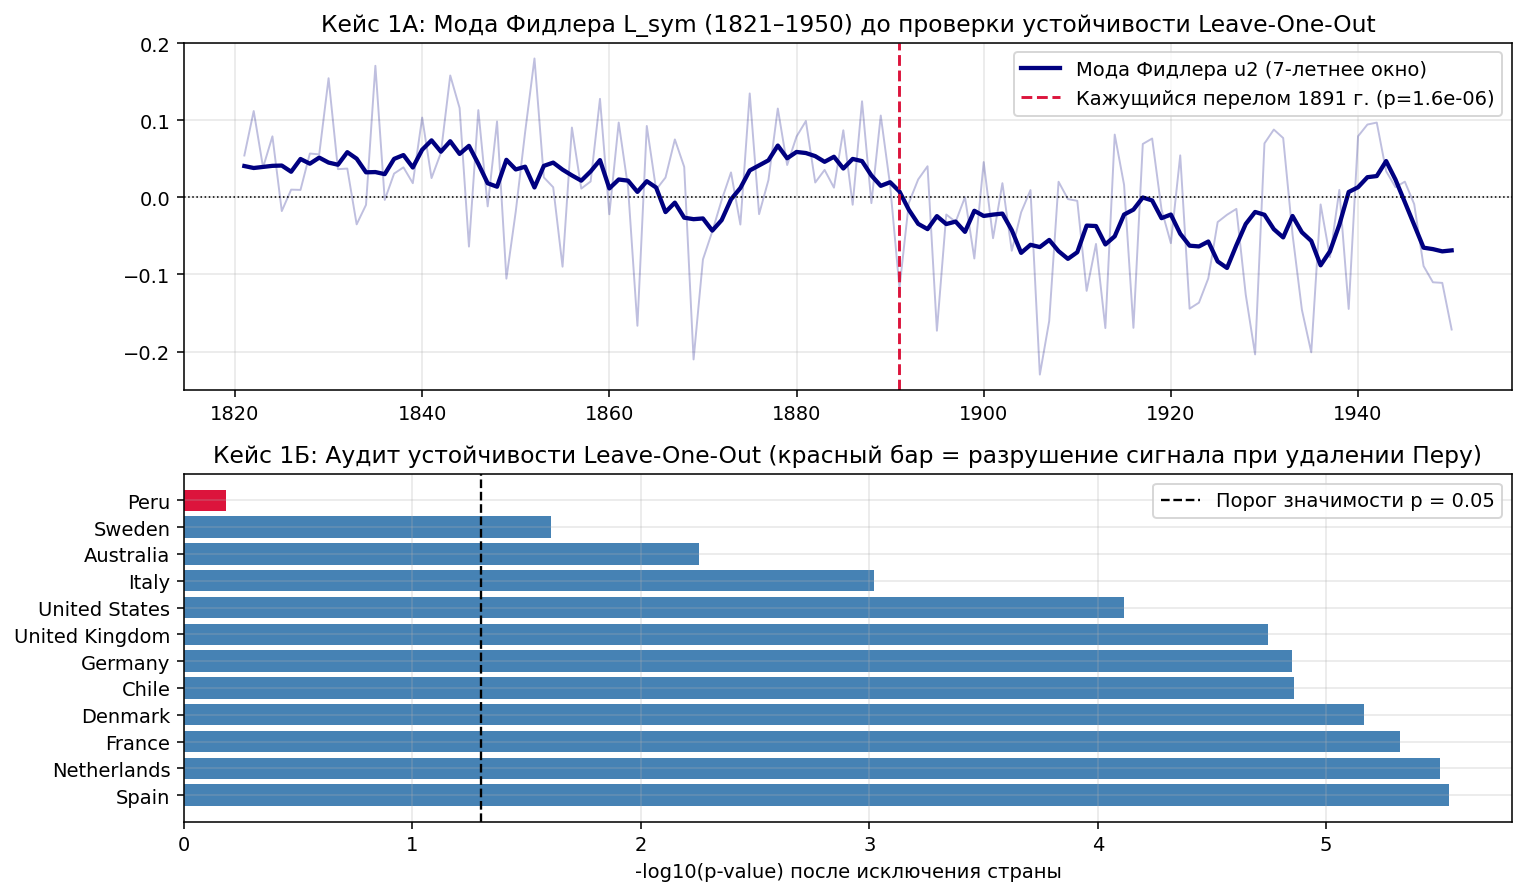

In [22]:
xlsx_files = [f for f in os.listdir(".") if f.endswith(".xlsx")]
if not xlsx_files:
    raise FileNotFoundError("Загрузите 'mpd2023_web.xlsx' в левую панель Colab (Files)!")

mpd_file = xlsx_files.pop(0)
df_mpd = pd.read_excel(mpd_file, sheet_name="Full data")
df_piv = df_mpd.pivot(index="year", columns="country", values="gdppc")

# 1. Срез 1820–1950 гг.
df_ind = df_piv.loc[1820:1950].dropna(axis=1)
countries_ind = df_ind.columns.tolist()
X_ind = df_ind.values.astype(float)
yrs_ind = df_ind.index.values

res1_ind = run_first_echelon_bypass(X_ind, countries_ind)
boot_ind = bootstrap_pr(X_ind, n_iter=300)

print(f"=== КЕЙС 1: MADDISON 1820–1950 ({len(yrs_ind)} лет x {len(countries_ind)} стран) ===")
print(f"Энергия 1-й моды: {res1_ind['energy_1']:.2%}")
print(f"PR(u1) = {res1_ind['pr_u1']:.3f} {boot_ind['u1_ci']} | PR(v1) = {res1_ind['pr_v1']:.3f} {boot_ind['v1_ci']}")

# 2. Второй эшелон (L_sym на лог-приростах) и слепой поиск перелома + Leave-One-Out
X_diff_ind = np.diff(np.log(X_ind), axis=0)
X_diff_ind_z = (X_diff_ind - X_diff_ind.mean(axis=0)) / X_diff_ind.std(axis=0)
yrs_diff_ind = yrs_ind[1:]

best_yr, min_p, p_scan, loo_ind, u2_ind = leave_one_out_scan(
    X_diff_ind_z, yrs_diff_ind, countries_ind, np.arange(1845, 1930), test_type="mean", k_nn=6
)
print(f"\nСлепой детектор сдвига среднего (L_sym): минимум p = {min_p:.2e} в {best_yr} г.")
for k, v in sorted(loo_ind.items(), key=lambda x: -x[1])[:3]:
    print(f"  Чувствительность при исключении '{k}': p = {v:.2e}")

# 3. Отрисовка и сохранение фигуры Кейса 1
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5))
u2_smooth = np.convolve(u2_ind, np.ones(7)/7, mode="same")
ax1.plot(yrs_diff_ind, u2_ind, color="navy", alpha=0.25, lw=1)
ax1.plot(yrs_diff_ind, u2_smooth, color="navy", lw=2.2, label="Мода Фидлера u2 (7-летнее окно)")
ax1.axhline(0, color="black", ls=":", lw=0.8)
ax1.axvline(best_yr, color="crimson", ls="--", lw=1.5, label=f"Кажущийся перелом {best_yr} г. (p={min_p:.1e})")
ax1.set_title("Кейс 1А: Мода Фидлера L_sym (1821–1950) до проверки устойчивости Leave-One-Out")
ax1.legend()
ax1.grid(True, alpha=0.3)

names_sorted = [k for k, _ in sorted(loo_ind.items(), key=lambda x: x[1])]
pvals_sorted = [v for _, v in sorted(loo_ind.items(), key=lambda x: x[1])]
colors_bar = ["crimson" if p > 0.05 else "steelblue" for p in pvals_sorted]
ax2.barh(names_sorted, -np.log10(pvals_sorted), color=colors_bar)
ax2.axvline(-np.log10(0.05), color="black", ls="--", lw=1.2, label="Порог значимости p = 0.05")
ax2.set_xlabel("-log10(p-value) после исключения страны")
ax2.set_title("Кейс 1Б: Аудит устойчивости Leave-One-Out (красный бар = разрушение сигнала при удалении Перу)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/case1_maddison_1820_1950.png")
plt.show()


=== КЕЙС 2: ALLEN-UNGER ПШЕНИЦА 1650–1800 (151 лет x 25 городов) ===
Bypass: PR(u1) = 0.155 | PR(v1) = 0.768 | Лидер: England (7.1%)
Gated (L_sym): PR(u2) = 0.585 (рост равномерности в 3.8 раза)


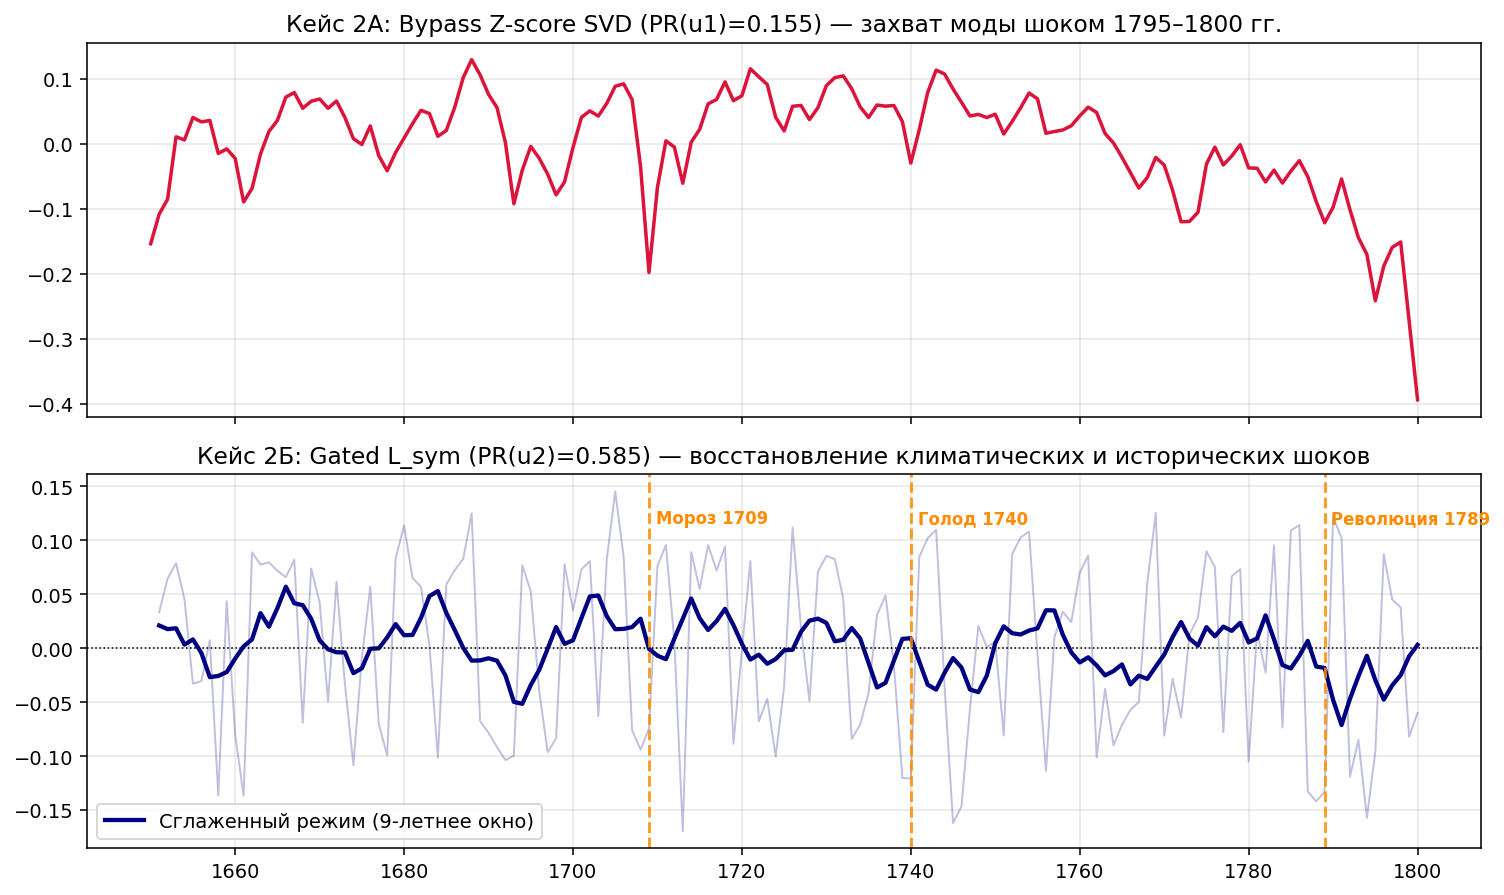

In [23]:
archives = [f for f in os.listdir(".") if "ipvxmw" in f.lower() or f.endswith(".zip")]
if not archives:
    raise FileNotFoundError("Загрузите 'doi-10.34894-ipvxmw.zip' в левую панель Colab (Files)!")

arch_file = archives.pop(0)
extract_dir = "allen_unger_data"
if not os.path.exists(extract_dir):
    with zipfile.ZipFile(arch_file, "r") as z:
        z.extractall(extract_dir)

wheat_files = sorted(glob.glob(f"{extract_dir}/**/*_Wheat.csv", recursive=True))
wheat_series = {}
for path in wheat_files:
    try:
        df_c = pd.read_csv(path, low_memory=False)
        yr_col = next(c for c in df_c.columns if "year" in str(c).lower())
        num_cols = [c for c in df_c.select_dtypes(include=[np.number]).columns if c != yr_col]
        silver_cols = [c for c in num_cols if "silver" in str(c).lower() or "gram" in str(c).lower()]
        val_col = silver_cols.pop(0) if silver_cols else num_cols[-1]
        city = os.path.basename(path).replace("_Wheat.csv", "")
        s = df_c.groupby(yr_col)[val_col].mean().dropna()
        if len(s) >= 50:
            wheat_series[city] = s
    except Exception:
        pass

df_w_all = pd.DataFrame(wheat_series).sort_index()
df_sub = df_w_all.loc[1650:1800]
valid_cities = df_sub.columns[df_sub.notna().mean() >= 0.85]
df_clean = df_sub[valid_cities].interpolate(method="linear").dropna()

cities_w = df_clean.columns.tolist()
X_w = df_clean.values.astype(float)
yrs_w = df_clean.index.values

res1_w = run_first_echelon_bypass(X_w, cities_w)
X_diff_w = np.diff(np.log(np.maximum(X_w, 1e-6)), axis=0)
X_diff_wz = (X_diff_w - X_diff_w.mean(axis=0)) / X_diff_w.std(axis=0)
_, _, evecs_w, gap_w = build_lsym_and_fiedler(X_diff_wz, k_nn=8)
u2_w = evecs_w[:, 1]
pr_u2_w = participation_ratio(u2_w)

print(f"=== КЕЙС 2: ALLEN-UNGER ПШЕНИЦА 1650–1800 ({len(yrs_w)} лет x {len(cities_w)} городов) ===")
print(f"Bypass: PR(u1) = {res1_w['pr_u1']:.3f} | PR(v1) = {res1_w['pr_v1']:.3f} | Лидер: {res1_w['top_label']} ({res1_w['top_share']:.1%})")
print(f"Gated (L_sym): PR(u2) = {pr_u2_w:.3f} (рост равномерности в {pr_u2_w / res1_w['pr_u1']:.1f} раза)")

# Отрисовка и сохранение фигуры Кейса 2
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ax1.plot(yrs_w, res1_w["U"][:, 0], color="crimson", lw=1.8)
ax1.set_title(f"Кейс 2А: Bypass Z-score SVD (PR(u1)={res1_w['pr_u1']:.3f}) — захват моды шоком 1795–1800 гг.")
ax1.grid(True, alpha=0.3)

u2_w_smooth = np.convolve(u2_w, np.ones(9)/9, mode="same")
ax2.plot(yrs_w[1:], u2_w, color="navy", alpha=0.25, lw=1)
ax2.plot(yrs_w[1:], u2_w_smooth, color="navy", lw=2.2, label="Сглаженный режим (9-летнее окно)")
ax2.axhline(0, color="black", ls=":", lw=0.8)
ymin, ymax = ax2.get_ylim()
for yr, lbl in [(1709, "Мороз 1709"), (1740, "Голод 1740"), (1789, "Революция 1789")]:
    ax2.axvline(yr, color="darkorange", ls="--", alpha=0.85)
    ax2.text(yr + 0.8, ymax * 0.72, lbl, color="darkorange", fontsize=8.5, fontweight="bold")
ax2.set_title(f"Кейс 2Б: Gated L_sym (PR(u2)={pr_u2_w:.3f}) — восстановление климатических и исторических шоков")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/case2_allen_unger_wheat_1650_1800.png")
plt.show()


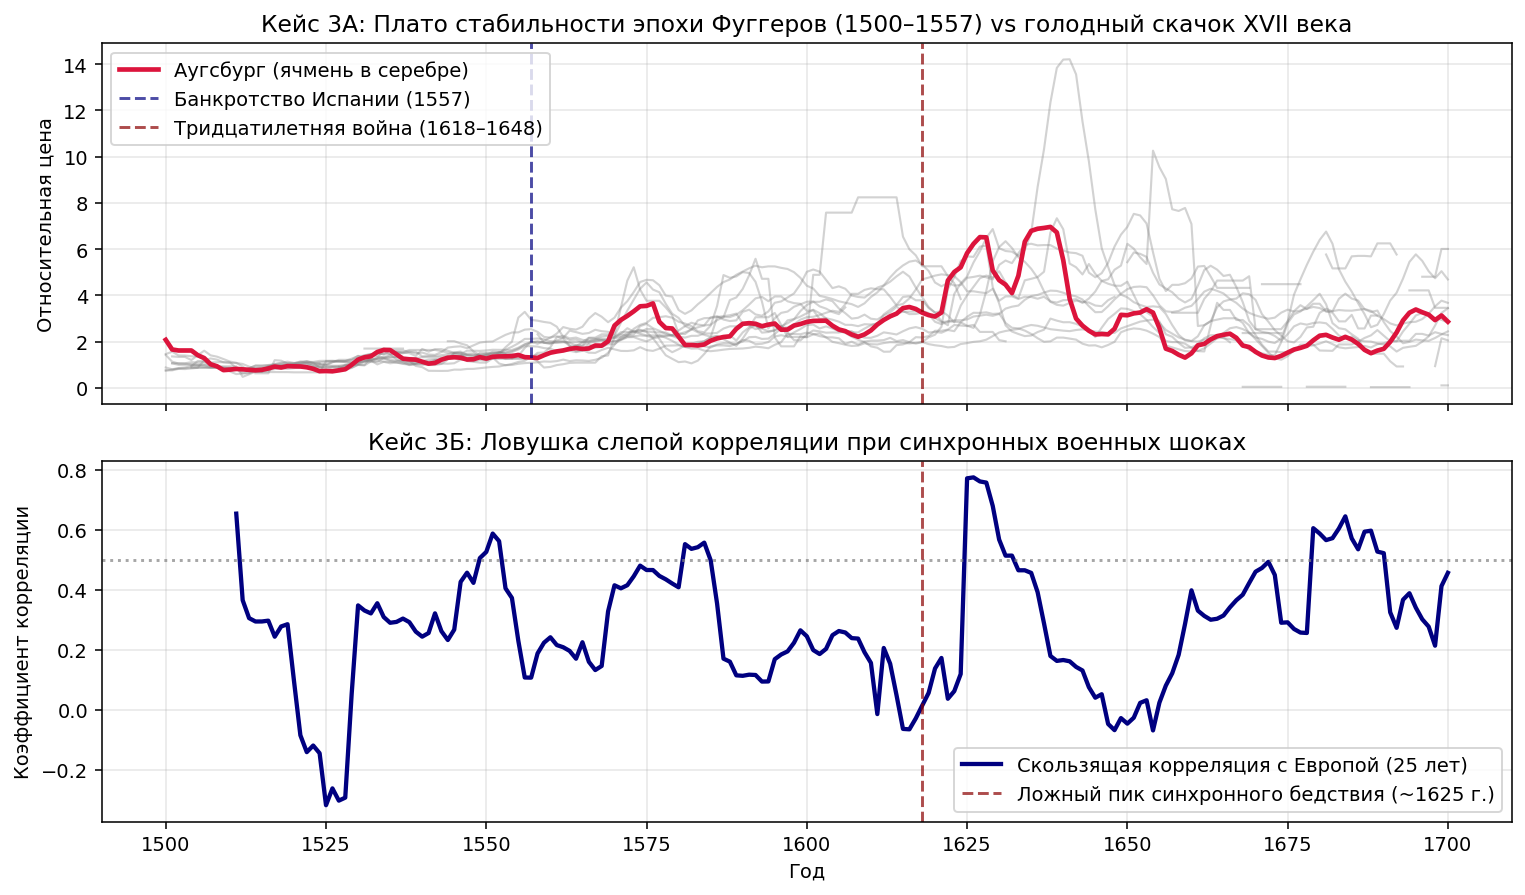

In [24]:
barley_files = sorted(glob.glob(f"{extract_dir}/**/*_Barley.csv", recursive=True))
series_barley = {}
for path in barley_files:
    try:
        df_c = pd.read_csv(path, low_memory=False)
        yr_col = next(c for c in df_c.columns if "year" in str(c).lower())
        num_cols = [c for c in df_c.select_dtypes(include=[np.number]).columns if c != yr_col]
        silver_cols = [c for c in num_cols if "silver" in str(c).lower() or "gram" in str(c).lower()]
        val_col = silver_cols.pop(0) if silver_cols else num_cols[-1]
        city = os.path.basename(path).replace("_Barley.csv", "")
        s = df_c.groupby(yr_col)[val_col].mean().dropna()
        if s.index.min() <= 1525 and s.index.max() >= 1660:
            series_barley[city] = s
    except Exception:
        pass

df_b = pd.DataFrame(series_barley).loc[1500:1700]
other_cities = [c for c in df_b.columns if c != "Augsburg"]
eu_mean = df_b[other_cities].mean(axis=1)
rolling_corr = df_b["Augsburg"].rolling(25, min_periods=10).corr(eu_mean)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
df_norm = df_b / df_b.loc[1500:1530].mean()
for col in other_cities:
    ax1.plot(df_norm.index, df_norm[col].rolling(7, min_periods=1).mean(), color="gray", alpha=0.35, lw=1.1)
ax1.plot(df_norm.index, df_norm["Augsburg"].rolling(7, min_periods=1).mean(), color="crimson", lw=2.4, label="Аугсбург (ячмень в серебре)")
ax1.axvline(1557, color="navy", ls="--", alpha=0.7, label="Банкротство Испании (1557)")
ax1.axvline(1618, color="darkred", ls="--", alpha=0.7, label="Тридцатилетняя война (1618–1648)")
ax1.set_title("Кейс 3А: Плато стабильности эпохи Фуггеров (1500–1557) vs голодный скачок XVII века")
ax1.set_ylabel("Относительная цена")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(rolling_corr.index, rolling_corr, color="navy", lw=2.2, label="Скользящая корреляция с Европой (25 лет)")
ax2.axhline(0.5, color="gray", ls=":", alpha=0.7)
ax2.axvline(1618, color="darkred", ls="--", alpha=0.7, label="Ложный пик синхронного бедствия (~1625 г.)")
ax2.set_title("Кейс 3Б: Ловушка слепой корреляции при синхронных военных шоках")
ax2.set_ylabel("Коэффициент корреляции")
ax2.set_xlabel("Год")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/case3_augsburg_1500_1700.png")
plt.show()


In [25]:
summary_df = pd.DataFrame([
    {
        "Полигон": "Maddison 1820–1950 (ВВП)",
        "Размерность (N x P)": f"{len(yrs_ind)} x {len(countries_ind)}",
        "Энергия моды 1": f"{res1_ind['energy_1']:.1%}",
        "PR(u1) время": round(res1_ind["pr_u1"], 3),
        "PR(v1) объекты": round(res1_ind["pr_v1"], 3),
        "PR(u2) L_sym": round(participation_ratio(u2_ind), 3),
        "Главный диагноз аудита": "Маскировка трендом + ложный перелом 1891 г. из-за Перу (LOO p=0.65)"
    },
    {
        "Полигон": "Allen–Unger 1650–1800 (Пшеница)",
        "Размерность (N x P)": f"{len(yrs_w)} x {len(cities_w)}",
        "Энергия моды 1": f"{res1_w['energy_1']:.1%}",
        "PR(u1) время": round(res1_w["pr_u1"], 3),
        "PR(v1) объекты": round(res1_w["pr_v1"], 3),
        "PR(u2) L_sym": round(pr_u2_w, 3),
        "Главный диагноз аудита": "Захват моды шоком 1795–1800 гг. + вложенные дубли (England/Tuscany)"
    }
])

print("\n=== СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ АУДИТА ===")
display(summary_df)
summary_df.to_csv("figures/audit_summary_table.csv", index=False)

with zipfile.ZipFile("results_bundle.zip", "w") as zout:
    for fname in glob.glob("figures/*"):
        zout.write(fname)

print("\nВсе графики и сводная таблица упакованы в 'results_bundle.zip' — можно скачивать и выкладывать на GitHub!")



=== СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ АУДИТА ===


,Полигон,Размерность (N x P),Энергия моды 1,PR(u1) время,PR(v1) объекты,PR(u2) L_sym,Главный диагноз аудита
0,Maddison 1820–1950 (ВВП),131 x 12,89.6%,0.485,0.998,0.348,Маскировка трендом + ложный перелом 1891 г. из...
1,Allen–Unger 1650–1800 (Пшеница),151 x 25,44.7%,0.155,0.768,0.585,Захват моды шоком 1795–1800 гг. + вложенные ду...



Все графики и сводная таблица упакованы в 'results_bundle.zip' — можно скачивать и выкладывать на GitHub!
